<a href="https://colab.research.google.com/github/PsicoJazz/Analise_de_Sentimentos/blob/main/Analise_de_Texto_Sentimento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.layers import SimpleRNN, Dense, Activation, Embedding, LSTM, Bidirectional
from keras.utils import pad_sequences
from keras.datasets import imdb

**Carregando dados do IMDB**

In [4]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(path = 'imdb.npz',
                                                      num_words = None,
                                                      skip_top = 0,
                                                      maxlen = None,
                                                      seed = 113,
                                                      start_char = 1,
                                                      oov_char = 2,
                                                      index_from = 3)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


**Obter dicionário**

In [5]:
dicionario = imdb.get_word_index()
num_words = len(dicionario)
print ("Número total de palavras no dicionario: ", num_words)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Número total de palavras no dicionario:  88584


In [7]:
def Decoder(idx = 1):
  reverse_index = dict([(id, word) for (word, id) in dicionario.items()])
  sentenca = ' '.join([reverse_index.get(i - 3, '!') for i in x_train[idx]])
  return sentenca

**Pré-Processamento**

In [8]:
# Padronizando review com 100 palavras, reduzindo o modelo
num_words = 5000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words = num_words)

maxlen = 100
embedding = 16

In [11]:
# Tamanho da sentença
x_train = pad_sequences(x_train, maxlen = maxlen)
x_test = pad_sequences(x_test, maxlen = maxlen)

print (x_train[5])
decoded_review = Decoder(5)
print(decoded_review)

[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    1  778  128   74   12  630  163   15    4 1766    2 1051    2
   32   85  156   45   40  148  139  121  664  665   10   10 1361  173
    4  749    2   16 3804    8    4  226   65   12   43  127   24    2
   10   10]
! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! ! begins better than it ends funny that the russian ! crew ! all other actors it's like those scenes where documentary shots br br spoiler part the message ! was contrary to the whole story it just does not ! br br


**Modelo RNN LSTM**

In [14]:
modelo = keras.Sequential()
modelo.add(keras.Input(shape=(maxlen,)))
modelo.add(Embedding(num_words, embedding))
modelo.add(LSTM(10, return_sequences = True))
modelo.add(LSTM(10, return_sequences = False))
modelo.add(Dense(1, activation = 'sigmoid'))

modelo.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 16)        │        80,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 100, 10)        │         1,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 10)             │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,931 (320.04 KB)

 Trainable params: 81,931 (320.04 KB)

 Non-trainable params: 0 (0.00 B)

**Estrutura da rede**

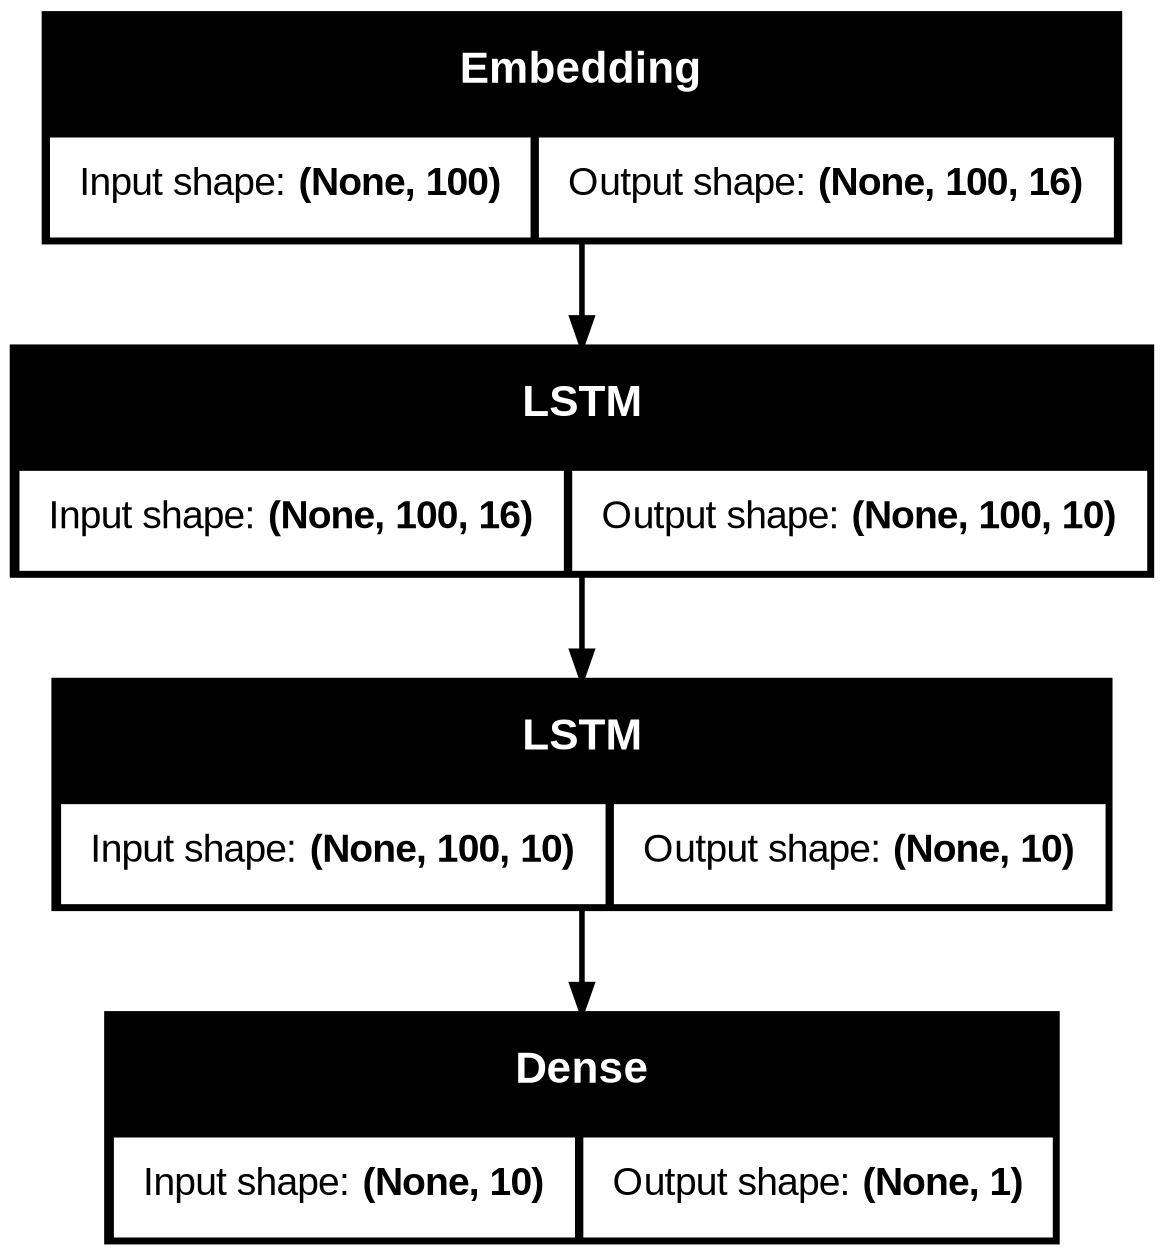

In [15]:
tf.keras.utils.plot_model(modelo, show_shapes = True)

**Treinamento da rede**

In [17]:
modelo.compile(loss = 'binary_crossentropy', optimizer = 'rmsprop', metrics = ['accuracy'])
history = modelo.fit(x_train, y_train, batch_size = 128, epochs = 10, validation_split = 0.1, verbose = 1)

Epoch 1/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 19s 89ms/step - accuracy: 0.7076 - loss: 0.5617 - val_accuracy: 0.8036 - val_loss: 0.4385
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.8266 - loss: 0.3997 - val_accuracy: 0.8364 - val_loss: 0.3750
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.8547 - loss: 0.3453 - val_accuracy: 0.8472 - val_loss: 0.3564
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.8662 - loss: 0.3258 - val_accuracy: 0.8192 - val_loss: 0.4152
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.8774 - loss: 0.2958 - val_accuracy: 0.8428 - val_loss: 0.3506
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 15s 87ms/step - accuracy: 0.8913 - loss: 0.2736 - val_accuracy: 0.8440 - val_loss: 0.3473
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 15s 85ms/step - accuracy: 0.8936 - loss: 0.2629 - val_accuracy: 0.8420 - val_loss: 0.3522
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 15s 86ms/step - accuracy: 0.9023 - loss: 0.2448 - 

**Avaliação do modelo**

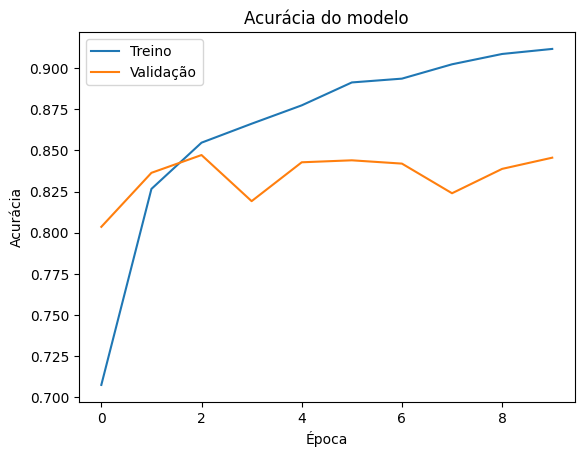

In [18]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Época')
plt.legend(['Treino', 'Validação'], loc = 'upper left')
plt.show()

**Função de custo**

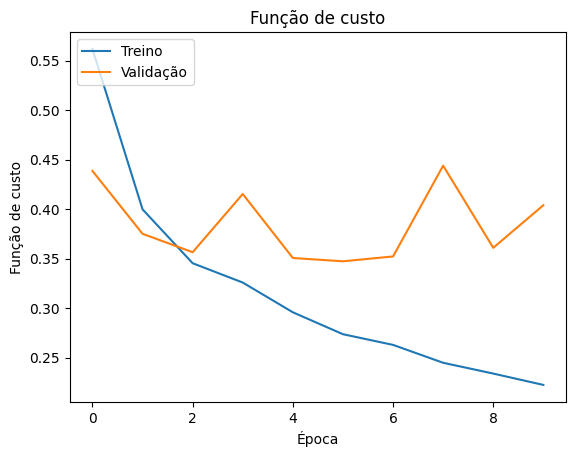

In [19]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Função de custo')
plt.ylabel('Função de custo')
plt.xlabel('Época')
plt.legend(['Treino', 'Validação'], loc = 'upper left')
plt.show()

**Acuracia no teste**

In [20]:
score = modelo.evaluate(x_test, y_test, verbose = 0)
print('Acurácia:', score[1]*100)
#

Acurácia: 84.61999893188477


**Confusion Matrix**

In [21]:
y_pred = modelo.predict(x_test)
y_pred = np.where(y_pred > 0.5, 1, 0)
cm = confusion_matrix(y_test, y_pred)
df1 = pd.DataFrame(cm, columns = ['Previsto Negativo', 'Previsto Positivo'], index = ['Real Negativo', 'Real Positivo'])
df1

782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step


,Previsto Negativo,Previsto Positivo
Real Negativo,10340,2160
Real Positivo,1685,10815


**Salvar modelo**

In [22]:
import json

# 1. Salvar o modelo em formato .keras
modelo.save('modelo_imdb.keras')
print("Modelo salvo com sucesso como 'modelo_imdb.keras'!")

# 2. Salvar o dicionário de palavras (filtrando para as 5000 mais frequentes usadas no modelo)
palavras_filtradas = {palavra: idx for palavra, idx in dicionario.items() if idx < 5000}

with open('word_index.json', 'w') as f:
    json.dump(palavras_filtradas, f)
print("Dicionário de palavras salvo com sucesso como 'word_index.json'!")

Modelo salvo com sucesso como 'modelo_imdb.keras'!
Dicionário de palavras salvo com sucesso como 'word_index.json'!
